In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (14,6)
print("✅ Colour Mode ON - 33 Charts Ready!")

✅ Colour Mode ON - 33 Charts Ready!


In [4]:
df = pd.read_excel(r"C:\Users\acer\OneDrive\Desktop\E-commerce_Customer_Segmentation_2026.xlsx")
print(f"Shape: {df.shape} | Columns: {len(df.columns)}")
df.head()

Shape: (50000, 53) | Columns: 53


,customer_id,customer_segment,segment_category,age,age_group,gender,country,city,income_bracket,education_level,...,customer_value_category,activity_status,health_status,churn_risk_category,rfm_category,profitability_category,engagement_level,behavior_segment,device_preference,clv_category
0,CUST-000001,Consumer,High Value Inactive,70,65+,Male,Canada,Winnipeg,150K+,Professional,...,High,Dormant,Excellent,Low,Potential Loyalists,High Profit,Low,Regular Buyer,Multi-Device,High CLV
1,CUST-000002,Premium,High Value Inactive,53,45-54,Female,Germany,Essen,25K-50K,High School,...,Medium,Inactive,Excellent,Medium,At Risk,High Profit,Low,Occasional Buyer,Desktop-First,High CLV
2,CUST-000003,Consumer,High Value Inactive,82,65+,Male,Mexico,Puebla,75K-100K,Bachelors,...,Very High,Dormant,Excellent,Very Low,Champions,High Profit,Low,Regular Buyer,Multi-Device,High CLV
3,CUST-000004,Enterprise,High Value Active,18,18-24,Male,Singapore,Singapore,150K+,Masters,...,Very High,Active,Excellent,Very Low,Champions,High Profit,High,Frequent Buyer,Mobile-First,High CLV
4,CUST-000005,Premium,High Value Active,64,55-64,Male,United Arab Emirates,Fujairah,150K+,PhD,...,Medium,Active,Fair,Medium,Loyal,High Profit,Medium,Occasional Buyer,Desktop-First,High CLV


In [5]:
print(f"Total Revenue: ${df['total_spent_usd'].sum():,.0f}")
print(f"Avg CLV: ${df['customer_lifetime_value_usd'].mean():,.0f}")
print(f"High CLV: {len(df[df['clv_category']=='High CLV'])} | High Churn: {len(df[df['churn_risk_category'].isin(['High','Very High'])])}")
df.describe().T.style.background_gradient(cmap='viridis')

Total Revenue: $2,513,327,308
Avg CLV: $57,722
High CLV: 41093 | High Churn: 2702


,count,mean,std,min,25%,50%,75%,max
age,50000.000000,45.648020,18.367950,18.000000,30.000000,45.000000,60.000000,84.000000
tenure_months,50000.000000,59.748240,34.310128,1.000000,30.000000,60.000000,90.000000,119.000000
total_purchases,50000.000000,99.418460,57.780178,0.000000,49.000000,99.000000,150.000000,199.000000
avg_order_value_usd,50000.000000,505.366911,285.604037,10.050000,259.067500,504.790000,752.702500,999.990000
total_spent_usd,50000.000000,50266.546156,44071.209164,0.000000,13893.577500,37541.625000,76811.242500,198574.140000
days_since_last_purchase,50000.000000,62.971240,93.281404,0.000000,2.000000,19.000000,77.000000,365.000000
return_count,50000.000000,9.511740,5.782592,0.000000,4.000000,10.000000,15.000000,19.000000
complaint_count,50000.000000,6.993800,4.324250,0.000000,3.000000,7.000000,11.000000,14.000000
satisfaction_score,50000.000000,3.007960,1.417976,1.000000,2.000000,3.000000,4.000000,5.000000
email_open_rate,50000.000000,0.500319,0.289515,0.000000,0.251000,0.500000,0.752000,1.000000


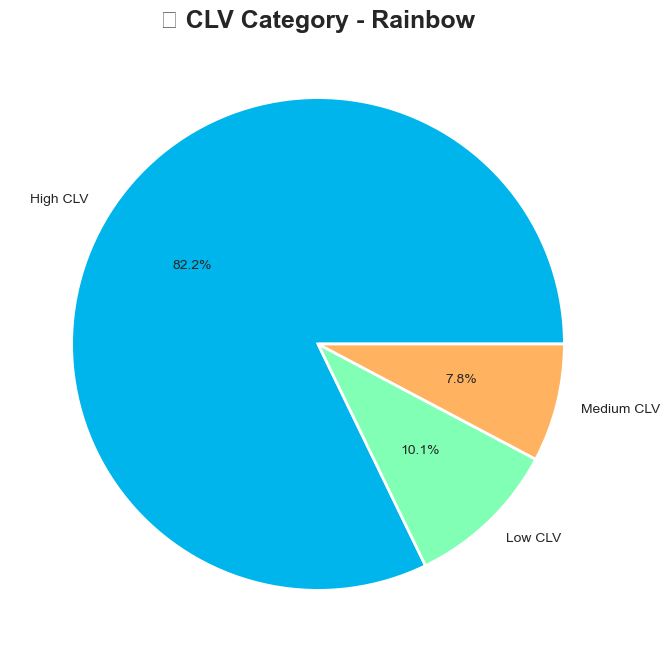

In [7]:
plt.figure(figsize=(8,8))
df['clv_category'].value_counts().plot.pie(
    autopct='%1.1f%%', 
    colors=sns.color_palette('rainbow',3), 
    wedgeprops={'edgecolor':'white','linewidth':2}
)
plt.title('💎 CLV Category - Rainbow', fontsize=18, fontweight='bold')
plt.ylabel('')
plt.show()

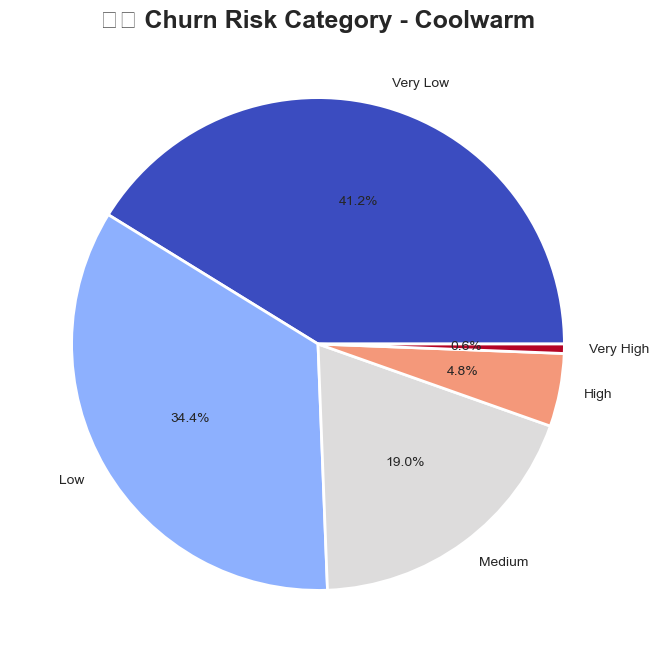

churn_risk_category
Very Low     20604
Low          17203
Medium        9491
High          2395
Very High      307
Name: count, dtype: int64


In [8]:
plt.figure(figsize=(8,8))
df['churn_risk_category'].value_counts().plot.pie(
    autopct='%1.1f%%', 
    cmap='coolwarm',
    wedgeprops={'edgecolor':'white','linewidth':2}
)
plt.title('⚠️ Churn Risk Category - Coolwarm', fontsize=18, fontweight='bold')
plt.ylabel('')
plt.show()

print(df['churn_risk_category'].value_counts())

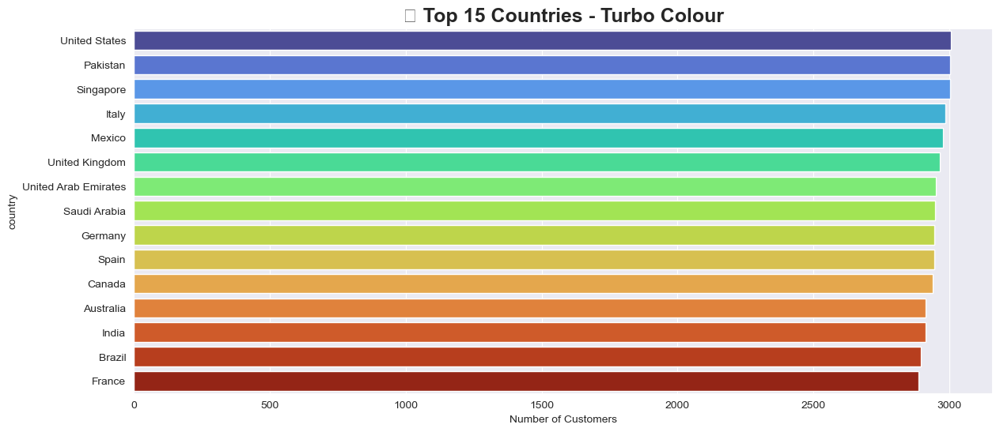

country
United States           3007
Pakistan                3004
Singapore               3003
Italy                   2986
Mexico                  2976
United Kingdom          2964
United Arab Emirates    2951
Saudi Arabia            2947
Germany                 2945
Spain                   2944
Canada                  2938
Australia               2914
India                   2914
Brazil                  2895
France                  2886
Name: count, dtype: int64


In [9]:
top_c = df['country'].value_counts().head(15)
plt.figure(figsize=(14,6))
sns.barplot(x=top_c.values, y=top_c.index, palette='turbo')
plt.title('🌍 Top 15 Countries - Turbo Colour', fontsize=18, fontweight='bold')
plt.xlabel('Number of Customers')
plt.show()

# Output table
print(top_c)

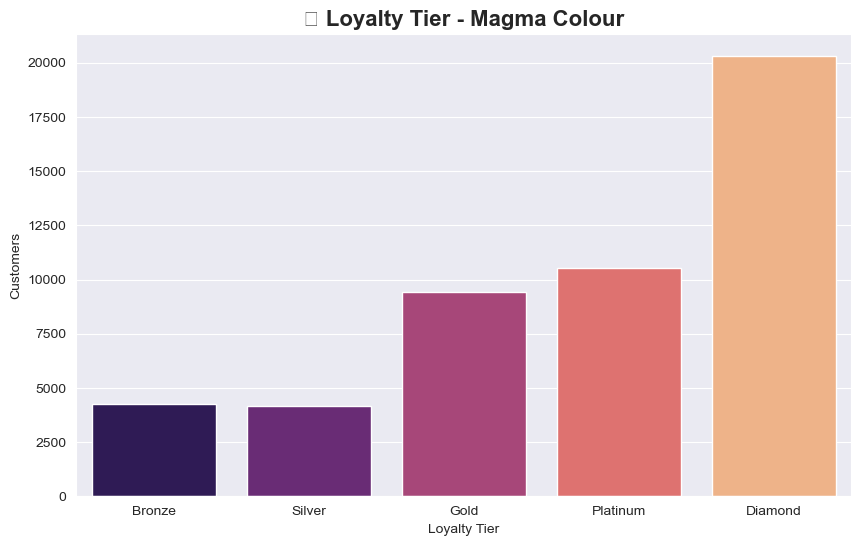

loyalty_tier
Bronze       4259
Diamond     20300
Gold         9446
Platinum    10535
Silver       4188
Name: count, dtype: int64


In [10]:
plt.figure(figsize=(10,6))
sns.countplot(
    data=df, 
    x='loyalty_tier', 
    palette='magma', 
    order=['Bronze','Silver','Gold','Platinum','Diamond']
)
plt.title('⭐ Loyalty Tier - Magma Colour', fontsize=16, fontweight='bold')
plt.xlabel('Loyalty Tier')
plt.ylabel('Customers')
plt.show()

# Table output
print(df['loyalty_tier'].value_counts().sort_index())

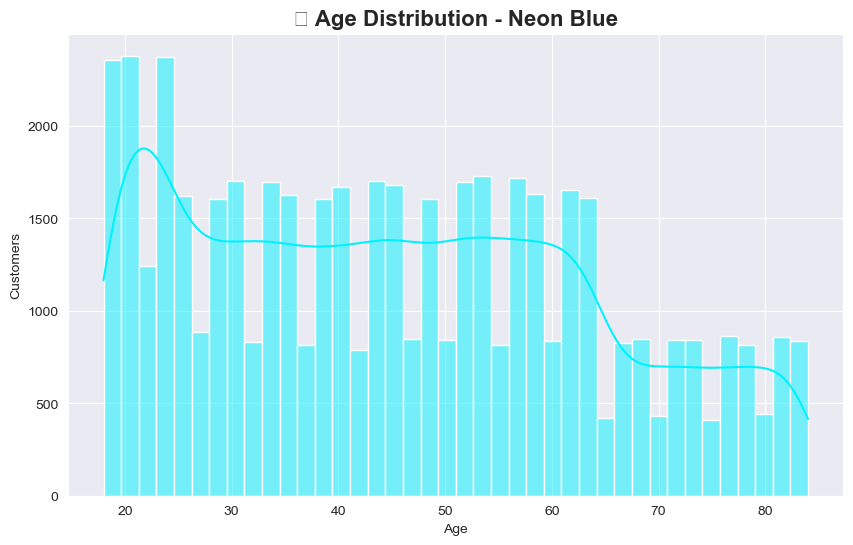

Min Age: 18, Max Age: 84, Avg: 45.6
age_group
65+      8440
45-54    8403
18-24    8349
25-34    8339
55-64    8266
35-44    8203
Name: count, dtype: int64


In [11]:
plt.figure(figsize=(10,6))
sns.histplot(df['age'], bins=40, kde=True, color='#00f2fe')
plt.title('👶 Age Distribution - Neon Blue', fontsize=16, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Customers')
plt.show()

# Stats output
print(f"Min Age: {df['age'].min()}, Max Age: {df['age'].max()}, Avg: {df['age'].mean():.1f}")
print(df['age_group'].value_counts())

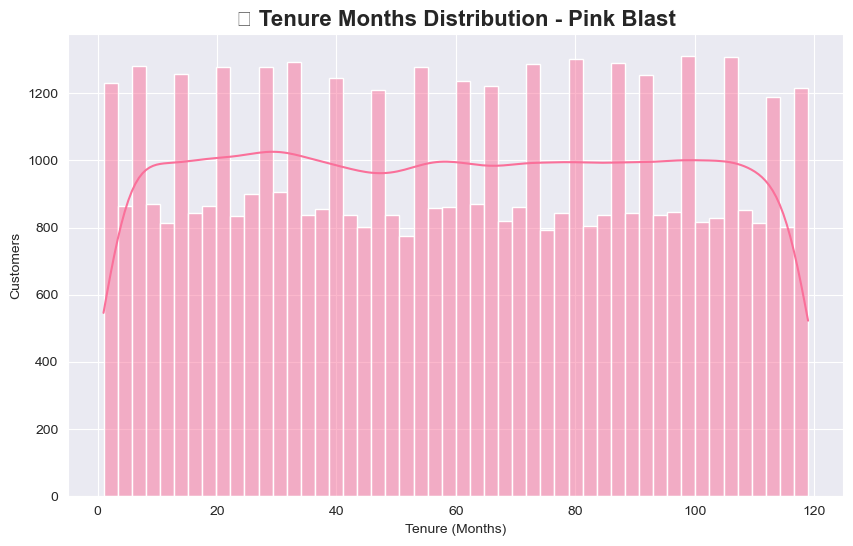

Min Tenure: 1 months, Max: 119 months
Avg Tenure: 59.7 months


In [12]:
plt.figure(figsize=(10,6))
sns.histplot(df['tenure_months'], bins=50, kde=True, color='#fa709a')
plt.title('📅 Tenure Months Distribution - Pink Blast', fontsize=16, fontweight='bold')
plt.xlabel('Tenure (Months)')
plt.ylabel('Customers')
plt.show()

# Output
print(f"Min Tenure: {df['tenure_months'].min()} months, Max: {df['tenure_months'].max()} months")
print(f"Avg Tenure: {df['tenure_months'].mean():.1f} months")

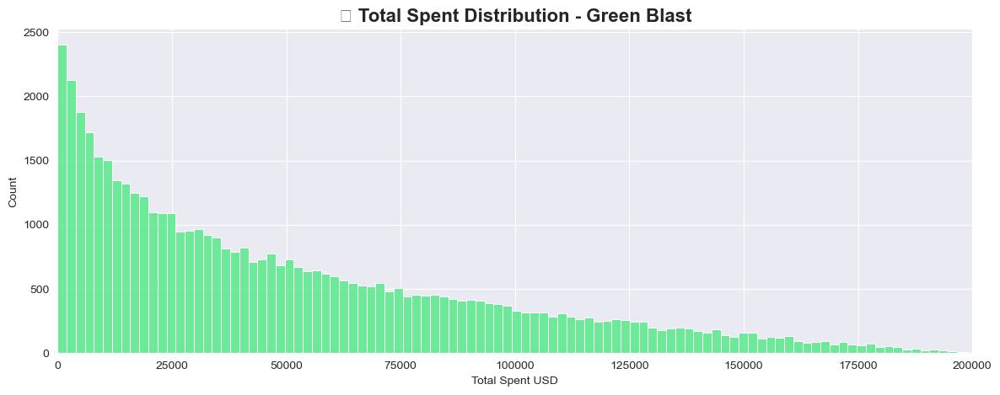

Total Revenue: $2,513,327,308
Min Spent: $0, Max: $198,574
Avg Spent: $50,267


In [13]:
plt.figure(figsize=(14,5))
sns.histplot(df['total_spent_usd'], bins=100, color='#43e97b')
plt.title('💰 Total Spent Distribution - Green Blast', fontsize=16, fontweight='bold')
plt.xlabel('Total Spent USD')
plt.xlim(0,200000)
plt.show()

# Money stats
print(f"Total Revenue: ${df['total_spent_usd'].sum():,.0f}")
print(f"Min Spent: ${df['total_spent_usd'].min():,.0f}, Max: ${df['total_spent_usd'].max():,.0f}")
print(f"Avg Spent: ${df['total_spent_usd'].mean():,.0f}")

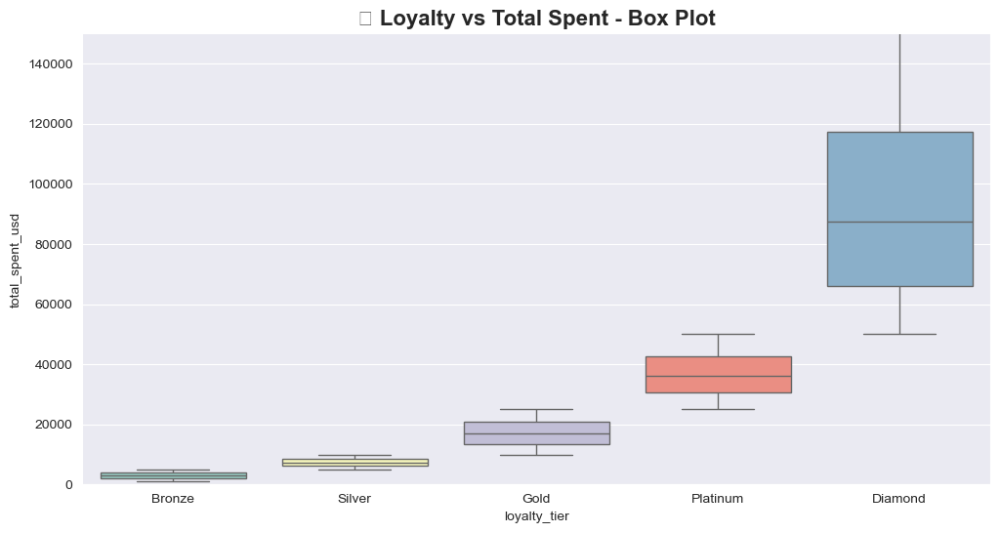

loyalty_tier
Diamond     94659.791382
Platinum    36674.788048
Gold        17076.353530
Silver       7396.517431
Bronze       2936.428136
Name: total_spent_usd, dtype: float64


In [14]:
plt.figure(figsize=(12,6))
sns.boxplot(
    data=df, 
    x='loyalty_tier', 
    y='total_spent_usd', 
    palette='Set3', 
    order=['Bronze','Silver','Gold','Platinum','Diamond']
)
plt.title('💎 Loyalty vs Total Spent - Box Plot', fontsize=16, fontweight='bold')
plt.ylim(0,150000)
plt.show()

# Table - Avg spent by loyalty
print(df.groupby('loyalty_tier')['total_spent_usd'].mean().sort_values(ascending=False))

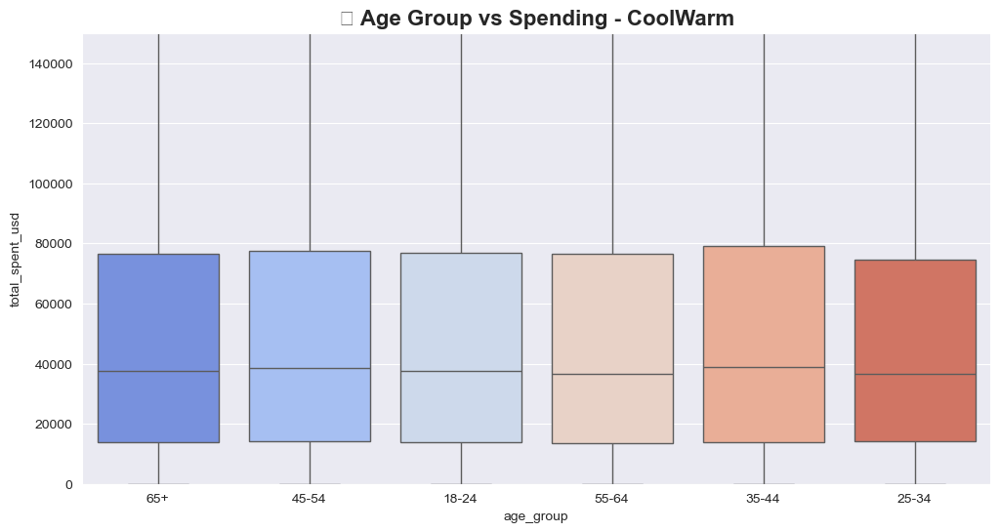

age_group
18-24    50364.792388
25-34    49570.089516
35-44    50981.229138
45-54    50663.640255
55-64    50006.095477
65+      50022.595117
Name: total_spent_usd, dtype: float64


In [15]:
plt.figure(figsize=(12,6))
sns.boxplot(
    data=df, 
    x='age_group', 
    y='total_spent_usd', 
    palette='coolwarm'
)
plt.title('👴 Age Group vs Spending - CoolWarm', fontsize=16, fontweight='bold')
plt.ylim(0,150000)
plt.show()

# Table
print(df.groupby('age_group')['total_spent_usd'].mean())

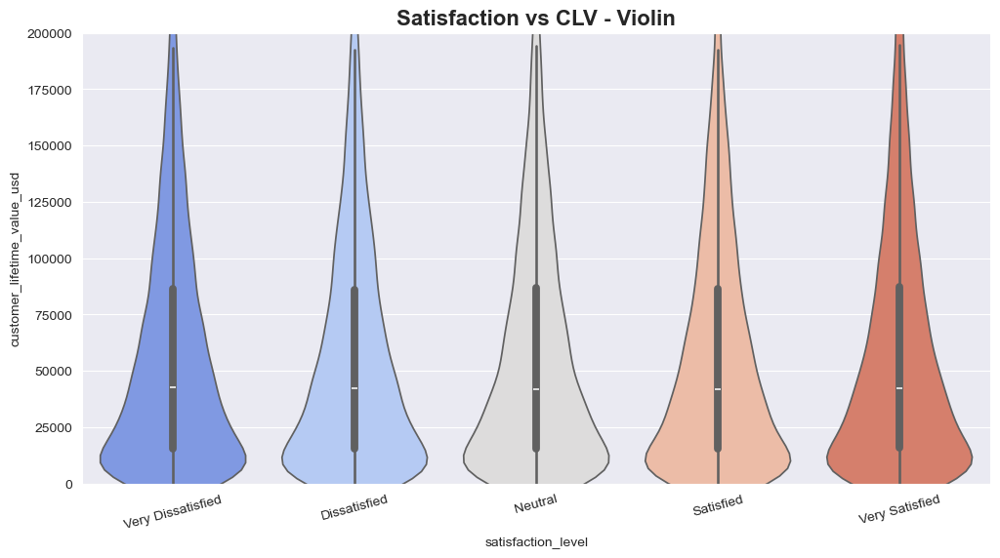

satisfaction_level
Dissatisfied         57307.791159
Satisfied            57447.288361
Very Dissatisfied    57773.970802
Neutral              57779.800302
Very Satisfied       58294.362270
Name: customer_lifetime_value_usd, dtype: float64


In [18]:
plt.figure(figsize=(12,6))
sns.violinplot(
    data=df, 
    x='satisfaction_level', 
    y='customer_lifetime_value_usd', 
    palette='coolwarm', 
    order=['Very Dissatisfied','Dissatisfied','Neutral','Satisfied','Very Satisfied']
)
plt.title('Satisfaction vs CLV - Violin', fontsize=16, fontweight='bold')
plt.xticks(rotation=15)
plt.ylim(0,200000)
plt.show()

# Table 
print(df.groupby('satisfaction_level')['customer_lifetime_value_usd'].mean().sort_values())

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel(r"C:\Users\acer\OneDrive\Desktop\E-commerce_Customer_Segmentation_2026.xlsx")  

print("DF Loaded")
print(df.shape)
print(df.head())

DF Loaded
(50000, 53)
   customer_id customer_segment     segment_category  age age_group  gender  \
0  CUST-000001         Consumer  High Value Inactive   70       65+    Male   
1  CUST-000002          Premium  High Value Inactive   53     45-54  Female   
2  CUST-000003         Consumer  High Value Inactive   82       65+    Male   
3  CUST-000004       Enterprise    High Value Active   18     18-24    Male   
4  CUST-000005          Premium    High Value Active   64     55-64    Male   

                country       city income_bracket education_level  ...  \
0                Canada   Winnipeg          150K+    Professional  ...   
1               Germany      Essen        25K-50K     High School  ...   
2                Mexico     Puebla       75K-100K       Bachelors  ...   
3             Singapore  Singapore          150K+         Masters  ...   
4  United Arab Emirates   Fujairah          150K+             PhD  ...   

  customer_value_category activity_status  health_status  

Numeric columns: ['age', 'tenure_months', 'total_purchases', 'avg_order_value_usd', 'total_spent_usd', 'days_since_last_purchase', 'return_count', 'complaint_count', 'satisfaction_score', 'email_open_rate', 'click_through_rate', 'conversion_rate', 'customer_lifetime_value_usd', 'customer_acquisition_cost_usd', 'customer_profitability_usd', 'recency_score', 'frequency_score', 'monetary_score', 'rfm_score', 'churn_risk_score', 'customer_health_score', 'dataset_year']


C:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


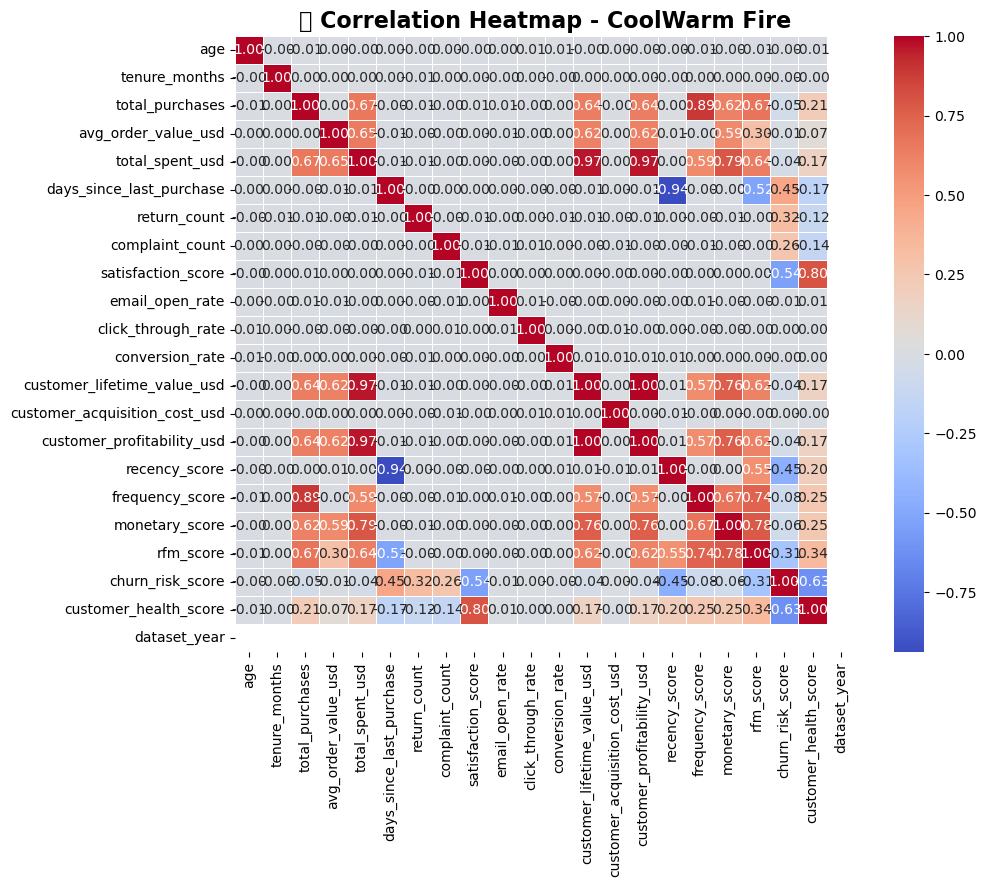

ALL DONE
           age  tenure_months  total_purchases  avg_order_value_usd  \
count  50000.0        50000.0          50000.0              50000.0   
mean      45.6           59.7             99.4                505.4   
std       18.4           34.3             57.8                285.6   
min       18.0            1.0              0.0                 10.0   
25%       30.0           30.0             49.0                259.1   
50%       45.0           60.0             99.0                504.8   
75%       60.0           90.0            150.0                752.7   
max       84.0          119.0            199.0               1000.0   

       total_spent_usd  days_since_last_purchase  return_count  \
count          50000.0                   50000.0       50000.0   
mean           50266.5                      63.0           9.5   
std            44071.2                      93.3           5.8   
min                0.0                       0.0           0.0   
25%            13893.

In [7]:
plt.figure(figsize=(10,8))
numeric_df = df.select_dtypes(include='number')

print("Numeric columns:", numeric_df.columns.tolist())

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('🔥 Correlation Heatmap - CoolWarm Fire', fontsize=16, fontweight='bold')
plt.show()

print("ALL DONE")
print(df.describe().round(1))

Using columns: ['age', 'tenure_months', 'total_purchases', 'total_spent_usd', 'churn_risk_score', 'customer_health_score', 'customer_lifetime_value_usd']


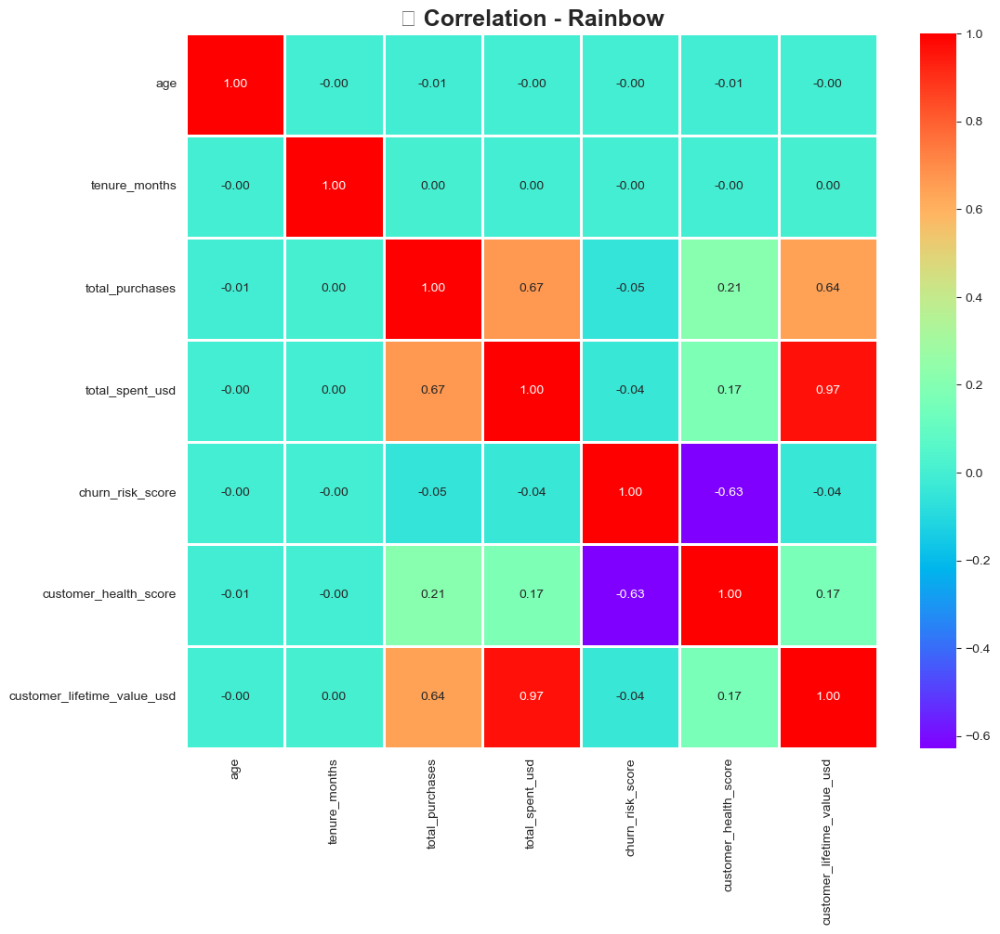

In [19]:
plt.figure(figsize=(12,10))
num_cols = ['age','tenure_months','total_purchases','total_spent_usd','churn_risk_score','customer_health_score','customer_lifetime_value_usd']
available_cols = [c for c in num_cols if c in df.columns]
print("Using columns:", available_cols)

sns.heatmap(
    df[available_cols].corr(), 
    annot=True, 
    cmap='rainbow', 
    linewidths=1,
    fmt='.2f',
    annot_kws={"size":10}
)
plt.title('💎 Correlation - Rainbow', fontsize=18, fontweight='bold')
plt.show()

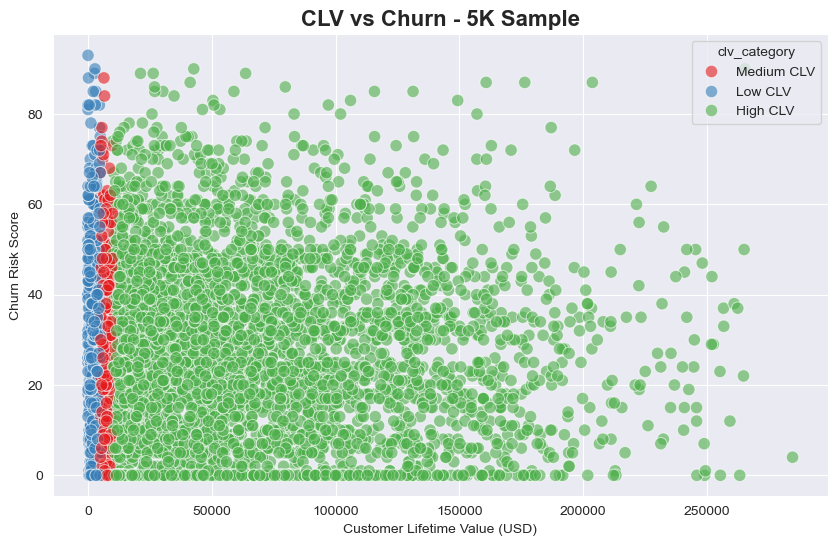

In [20]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df.sample(5000), 
    x='customer_lifetime_value_usd', 
    y='churn_risk_score', 
    hue='clv_category', 
    palette='Set1', 
    alpha=0.6,
    s=80
)
plt.title('CLV vs Churn - 5K Sample', fontsize=16, fontweight='bold')
plt.xlabel('Customer Lifetime Value (USD)')
plt.ylabel('Churn Risk Score')
plt.show()

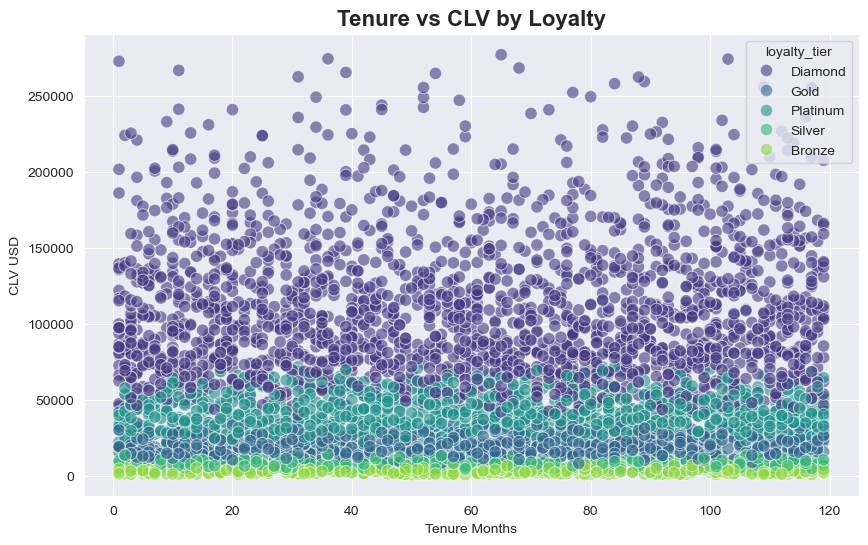

In [21]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df.sample(5000), 
    x='tenure_months', 
    y='customer_lifetime_value_usd', 
    hue='loyalty_tier', 
    palette='viridis',
    alpha=0.6,
    s=80
)
plt.title('Tenure vs CLV by Loyalty', fontsize=16, fontweight='bold')
plt.xlabel('Tenure Months')
plt.ylabel('CLV USD')
plt.show()

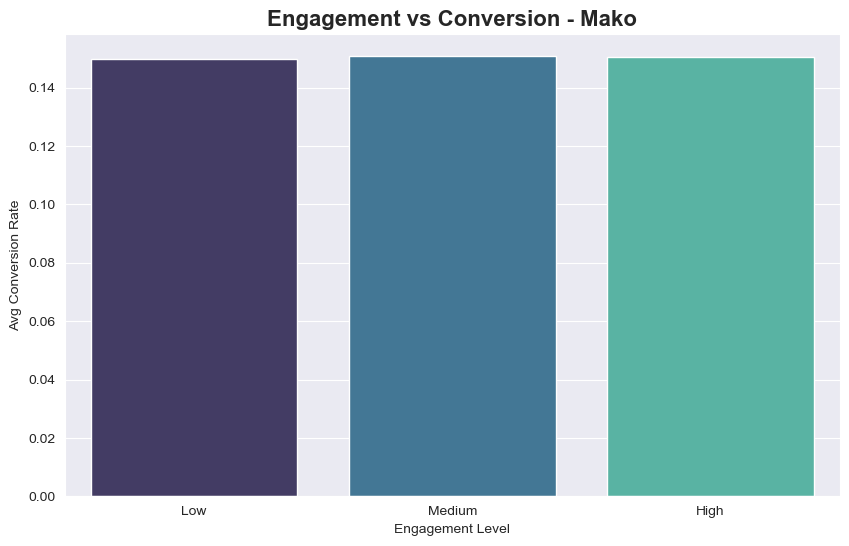

engagement_level
High      0.150429
Low       0.149844
Medium    0.150719
Name: conversion_rate, dtype: float64


In [22]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=df, 
    x='engagement_level', 
    y='conversion_rate', 
    palette='mako', 
    order=['Low','Medium','High'],
    ci=None
)
plt.title('Engagement vs Conversion - Mako', fontsize=16, fontweight='bold')
plt.xlabel('Engagement Level')
plt.ylabel('Avg Conversion Rate')
plt.show()

print(df.groupby('engagement_level')['conversion_rate'].mean())

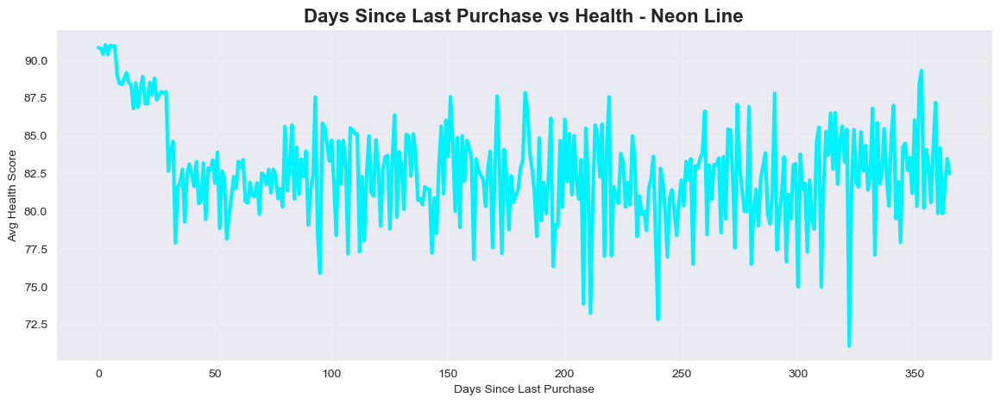

In [23]:
avg_health = df.groupby('days_since_last_purchase')['customer_health_score'].mean().reset_index()

plt.figure(figsize=(14,5))
plt.plot(
    avg_health['days_since_last_purchase'], 
    avg_health['customer_health_score'], 
    color='#00f2fe', 
    linewidth=3
)
plt.title('Days Since Last Purchase vs Health - Neon Line', fontsize=16, fontweight='bold')
plt.xlabel('Days Since Last Purchase')
plt.ylabel('Avg Health Score')
plt.grid(alpha=0.3)
plt.show()

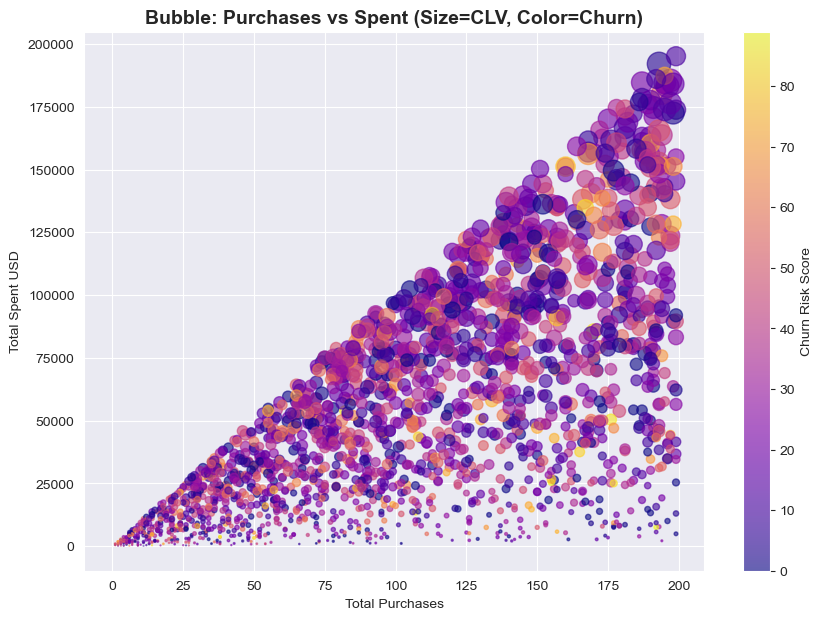

In [24]:
plt.figure(figsize=(10,7))
sample = df.sample(2000)

plt.scatter(
    sample['total_purchases'], 
    sample['total_spent_usd'], 
    s=sample['customer_lifetime_value_usd']/1000,  # Bubble size = CLV
    c=sample['churn_risk_score'], 
    cmap='plasma', 
    alpha=0.6
)
plt.colorbar(label='Churn Risk Score')
plt.title('Bubble: Purchases vs Spent (Size=CLV, Color=Churn)', fontsize=14, fontweight='bold')
plt.xlabel('Total Purchases')
plt.ylabel('Total Spent USD')
plt.show()

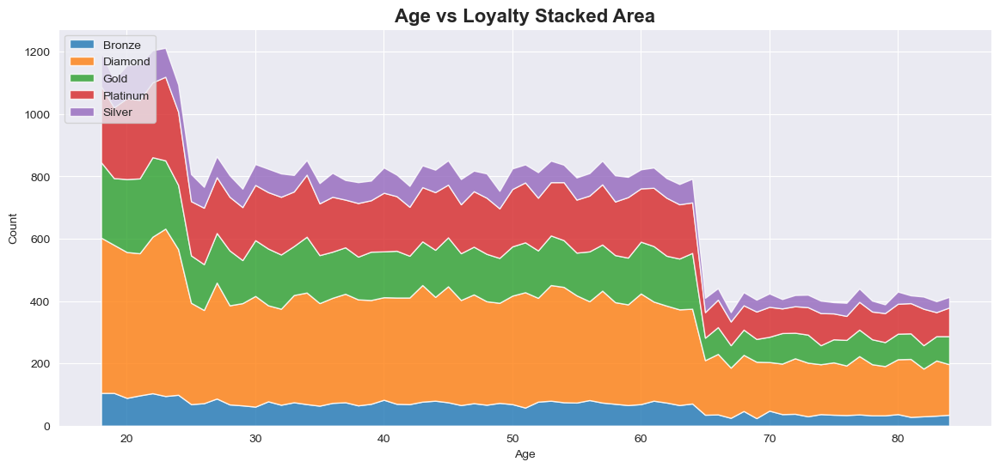

In [25]:
loyalty_age = df.groupby(['age','loyalty_tier']).size().unstack(fill_value=0)

plt.figure(figsize=(14,6))
plt.stackplot(
    loyalty_age.index,
    [loyalty_age[c] for c in loyalty_age.columns],
    labels=loyalty_age.columns,
    alpha=0.8
)
plt.legend(loc='upper left')
plt.title('Age vs Loyalty Stacked Area', fontsize=16, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

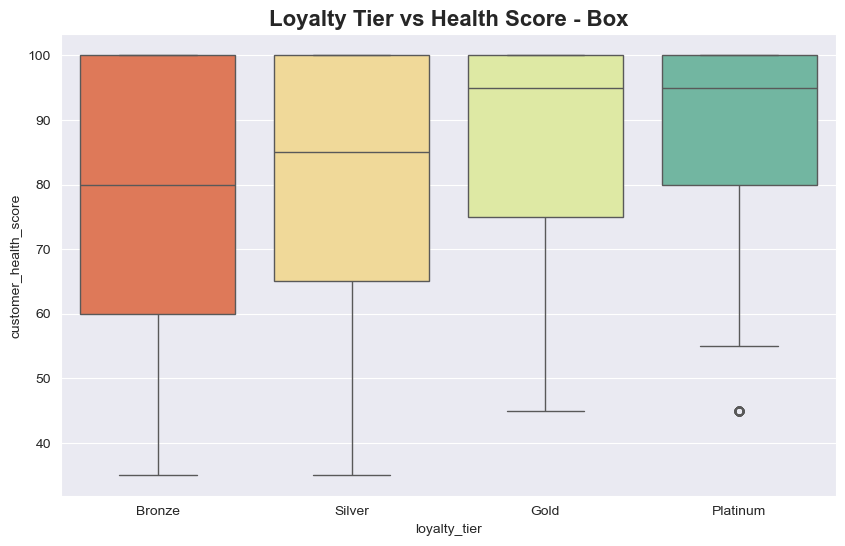

loyalty_tier
Bronze      78.660484
Diamond     89.615271
Gold        86.917743
Platinum    88.485050
Silver      79.573782
Name: customer_health_score, dtype: float64


In [30]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df, 
    x='loyalty_tier', 
    y='customer_health_score', 
    palette='Spectral',
    order=['Bronze','Silver','Gold','Platinum']
)
plt.title('Loyalty Tier vs Health Score - Box', fontsize=16, fontweight='bold')
plt.show()

print(df.groupby('loyalty_tier')['customer_health_score'].mean())

In [29]:
print(df.columns.tolist())

['customer_id', 'customer_segment', 'segment_category', 'age', 'age_group', 'gender', 'country', 'city', 'income_bracket', 'education_level', 'employment_type', 'marital_status', 'tenure_months', 'total_purchases', 'avg_order_value_usd', 'total_spent_usd', 'purchase_frequency', 'days_since_last_purchase', 'preferred_category_1', 'preferred_category_2', 'preferred_category_3', 'shopping_channel', 'device_used', 'payment_method', 'return_count', 'complaint_count', 'satisfaction_score', 'satisfaction_level', 'loyalty_tier', 'email_open_rate', 'click_through_rate', 'conversion_rate', 'social_media_presence', 'customer_lifetime_value_usd', 'customer_acquisition_cost_usd', 'customer_profitability_usd', 'recency_score', 'frequency_score', 'monetary_score', 'rfm_score', 'churn_risk_score', 'customer_health_score', 'dataset_year', 'customer_value_category', 'activity_status', 'health_status', 'churn_risk_category', 'rfm_category', 'profitability_category', 'engagement_level', 'behavior_segment'

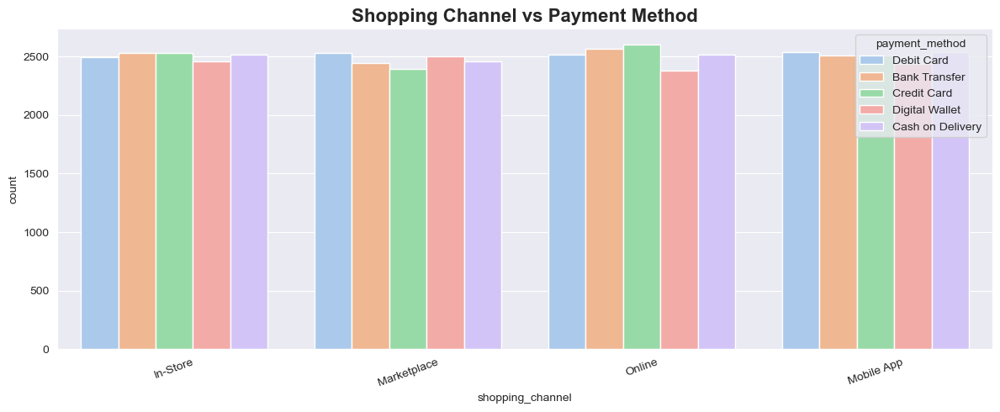

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,5))

sns.countplot(
    data=df,
    x='shopping_channel',
    hue='payment_method',
    palette='pastel'
)

plt.title('Shopping Channel vs Payment Method', fontsize=16, fontweight='bold')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

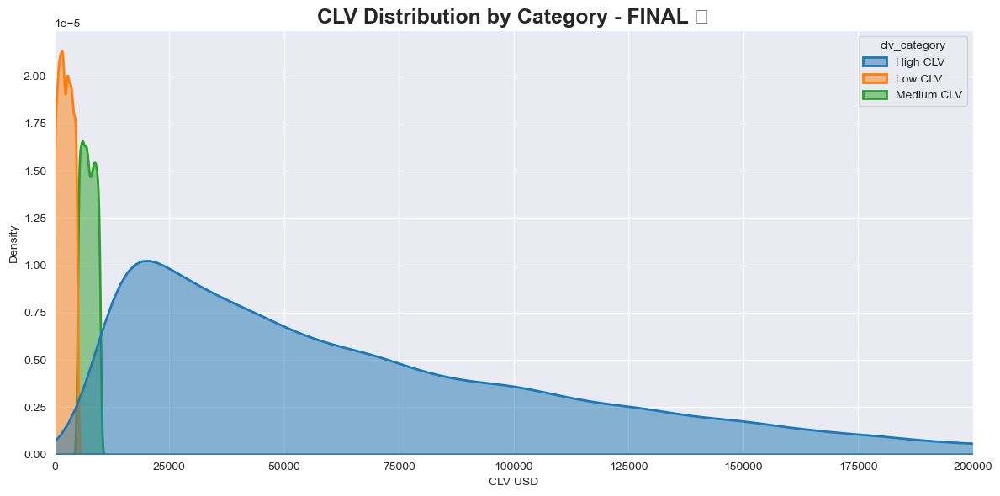

In [32]:
plt.figure(figsize=(12,6))
sns.kdeplot(
    data=df,
    x='customer_lifetime_value_usd',
    hue='clv_category',
    fill=True,
    palette='tab10',
    alpha=0.5,
    linewidth=2
)
plt.title('CLV Distribution by Category - FINAL 🎉', fontsize=18, fontweight='bold')
plt.xlabel('CLV USD')
plt.xlim(0,200000)
plt.tight_layout()
plt.show()

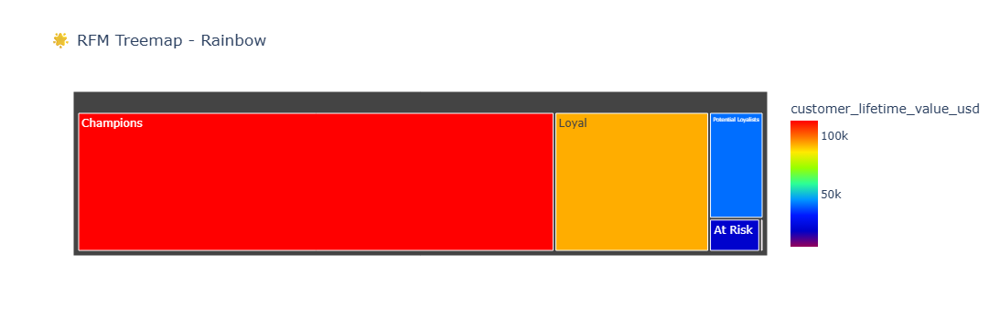

In [33]:
import plotly.express as px

fig = px.treemap(df, 
                 path=['rfm_category'], 
                 values='total_spent_usd', 
                 color='customer_lifetime_value_usd', 
                 color_continuous_scale='Rainbow', 
                 title='🌟 RFM Treemap - Rainbow')
fig.show()

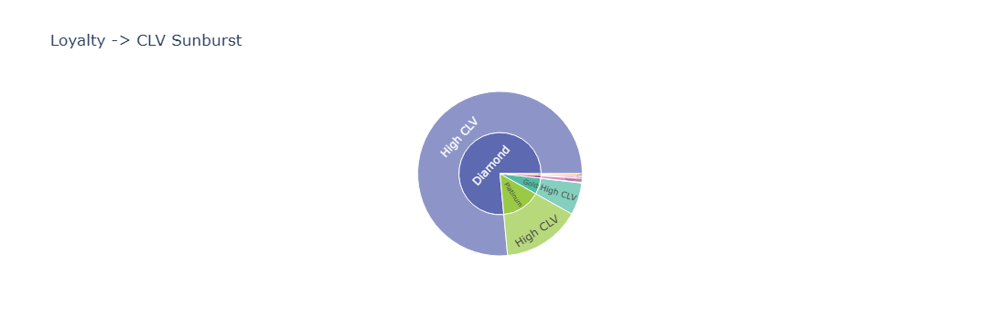

In [35]:
import plotly.express as px

df_sun = df.dropna(subset=['loyalty_tier','clv_category','total_spent_usd'])
df_sun = df_sun[df_sun['total_spent_usd'] > 0]  

fig = px.sunburst(df_sun, 
                  path=['loyalty_tier','clv_category'], 
                  values='total_spent_usd',
                  color='loyalty_tier',  
                  color_discrete_sequence=px.colors.qualitative.Vivid, 
                  title='Loyalty -> CLV Sunburst')
fig.show()

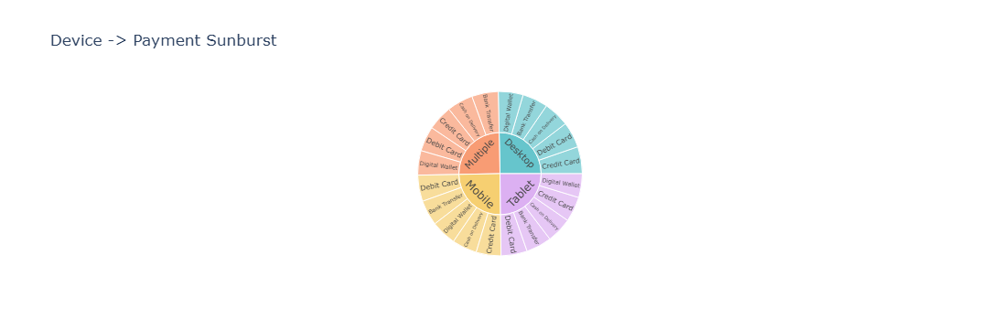

In [36]:
import plotly.express as px

df_sun2 = df.dropna(subset=['device_used','payment_method','total_spent_usd'])
df_sun2 = df_sun2[df_sun2['total_spent_usd'] > 0]

fig = px.sunburst(df_sun2, 
                  path=['device_used','payment_method'], 
                  values='total_spent_usd',
                  color='device_used',
                  color_discrete_sequence=px.colors.qualitative.Pastel,
                  title='Device -> Payment Sunburst')
fig.show()

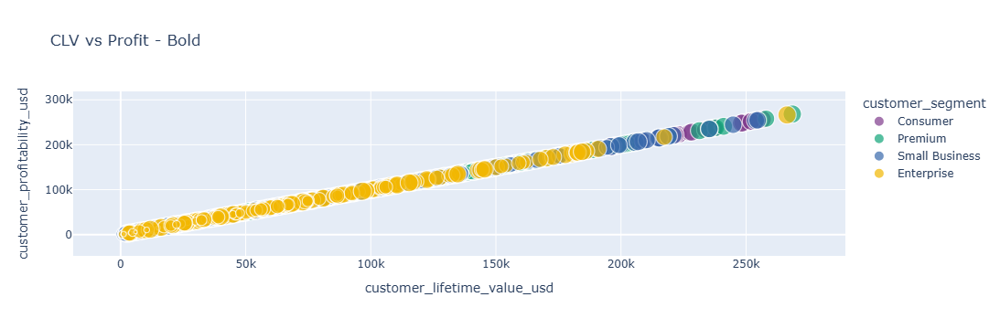

In [37]:
import plotly.express as px

df_scat = df.dropna(subset=['customer_lifetime_value_usd','customer_profitability_usd','customer_segment','total_purchases']).sample(3000)

fig = px.scatter(df_scat, 
                 x='customer_lifetime_value_usd', 
                 y='customer_profitability_usd', 
                 color='customer_segment', 
                 size='total_purchases',
                 size_max=20,
                 opacity=0.7,
                 color_discrete_sequence=px.colors.qualitative.Bold, 
                 title='CLV vs Profit - Bold')
fig.show()

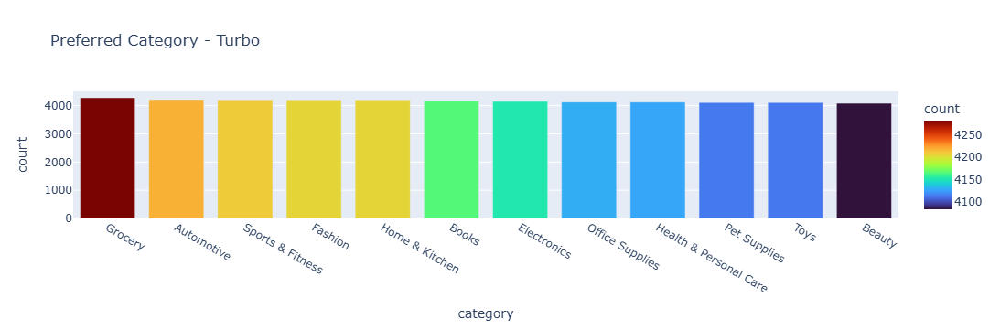

In [38]:
import plotly.express as px

cat_count = df['preferred_category_1'].value_counts().reset_index()
cat_count.columns=['category','count']

fig = px.bar(cat_count, 
             x='category', 
             y='count', 
             color='count', 
             color_continuous_scale='Turbo', 
             title='Preferred Category - Turbo')
fig.show()

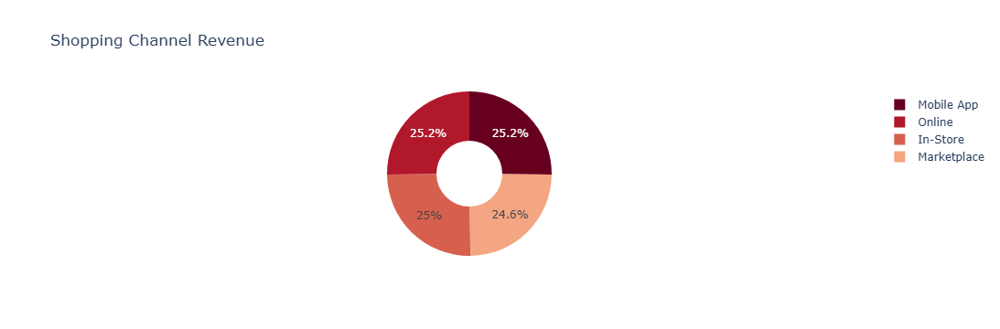

In [39]:
import plotly.express as px

fig = px.pie(df, 
             names='shopping_channel', 
             values='total_spent_usd', 
             hole=0.4, 
             color_discrete_sequence=px.colors.sequential.RdBu, 
             title='Shopping Channel Revenue')
fig.show()

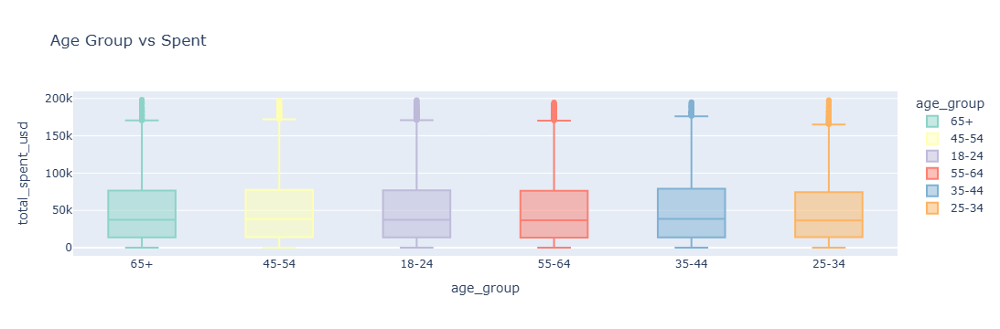

In [40]:
import plotly.express as px

fig = px.box(df, 
             x='age_group', 
             y='total_spent_usd', 
             color='age_group', 
             color_discrete_sequence=px.colors.qualitative.Set3,
             title='Age Group vs Spent')
fig.show()

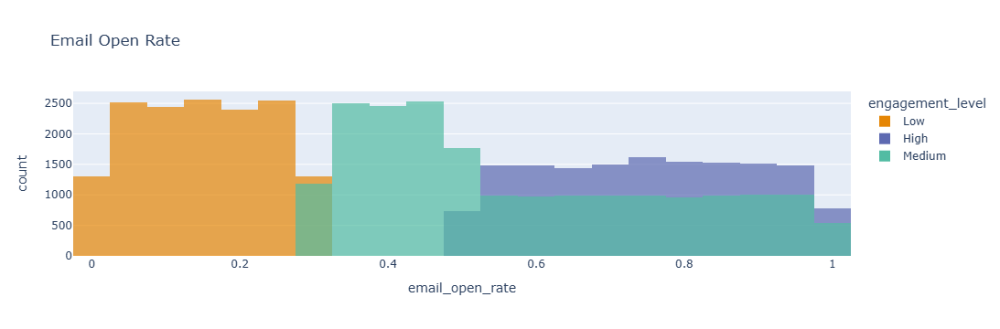

In [41]:
import plotly.express as px

fig = px.histogram(df, 
                   x='email_open_rate', 
                   color='engagement_level', 
                   nbins=50, 
                   color_discrete_sequence=px.colors.qualitative.Vivid, 
                   title='Email Open Rate',
                   barmode='overlay',
                   opacity=0.7)
fig.show()

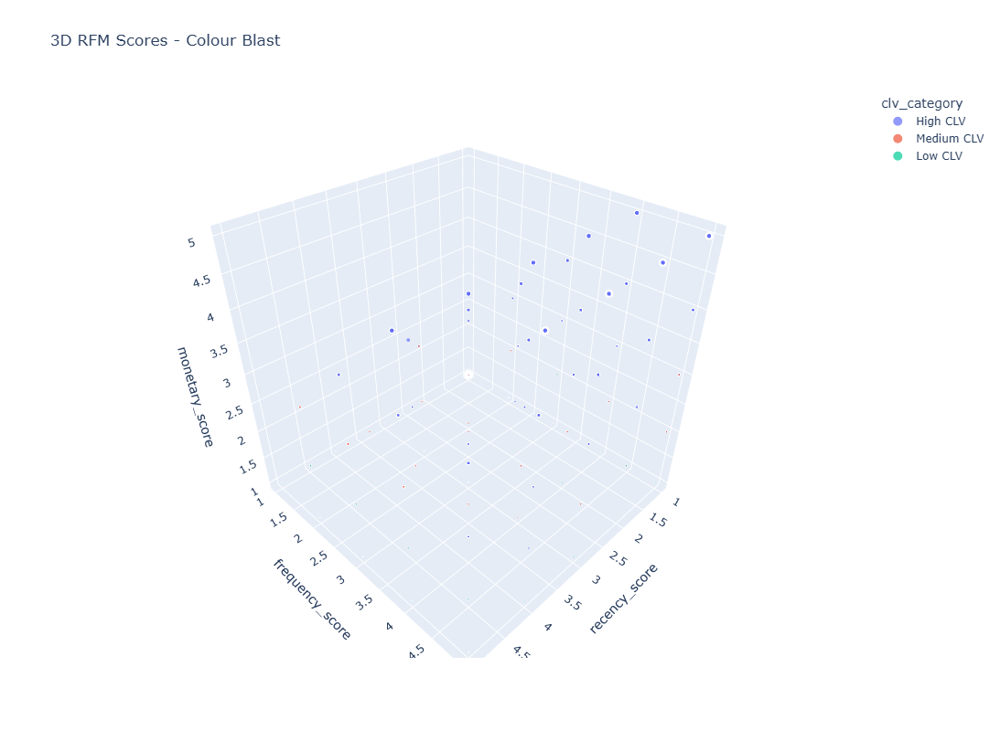

In [42]:
import plotly.express as pd
df_3d = df.sample(2000)

fig = px.scatter_3d(df_3d, 
                    x='recency_score', 
                    y='frequency_score', 
                    z='monetary_score', 
                    color='clv_category', 
                    size='total_spent_usd', 
                    size_max=15,
                    opacity=0.7,
                    title='3D RFM Scores - Colour Blast')
fig.update_layout(height=800)
fig.show()

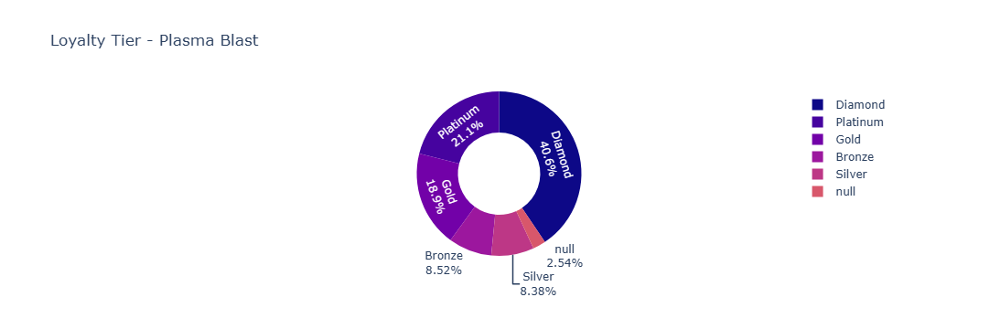

In [43]:
import plotly.express as px

fig = px.pie(df, 
             names='loyalty_tier', 
             color_discrete_sequence=px.colors.sequential.Plasma, 
             title='Loyalty Tier - Plasma Blast',
             hole=0.5)
fig.update_traces(textinfo='percent+label', textfont_size=12)
fig.show()

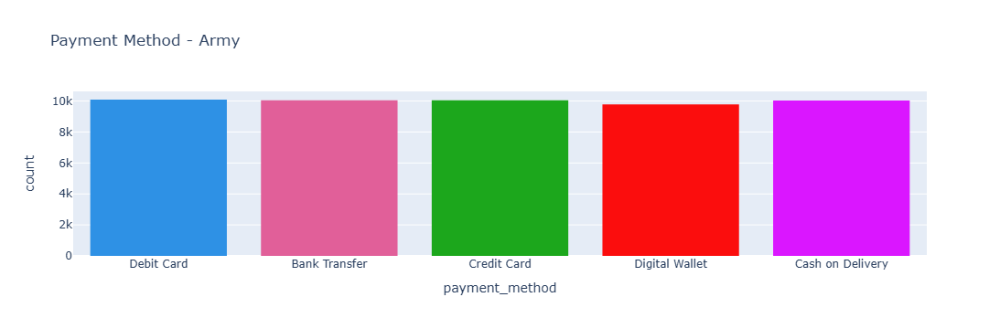

In [45]:
import plotly.express as px

fig = px.histogram(df, 
                   x='payment_method', 
                   color='payment_method', 
                   color_discrete_sequence=px.colors.qualitative.Dark24, 
                   title='Payment Method - Army')
fig.update_layout(showlegend=False)
fig.show()

Using CLV column: customer_lifetime_value_usd
Shape: (50000, 53)


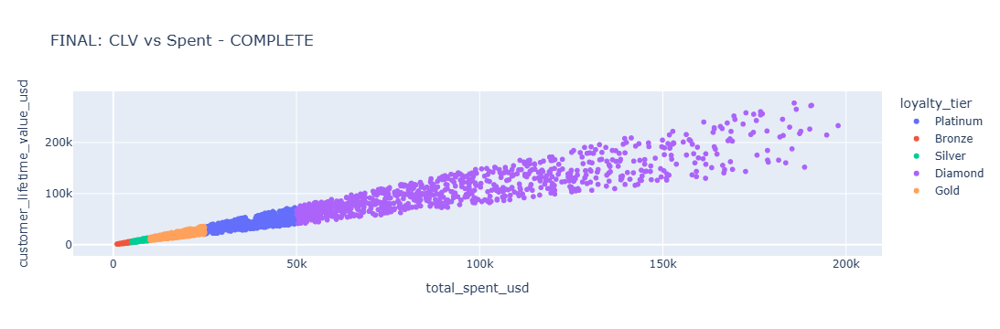

In [48]:
import plotly.express as px
clv_col = None
for col in ['predicted_clv', 'customer_lifetime_value_usd', 'clv', 'predicted_customer_lifetime_value']:
    if col in df.columns:
        clv_col = col
        break

print(f"Using CLV column: {clv_col}")
print(f"Shape: {df.shape}")

fig = px.scatter(df.dropna(subset=['total_spent_usd', clv_col]).sample(min(2000, len(df))),
                 x='total_spent_usd',
                 y=clv_col,
                 color='loyalty_tier' if 'loyalty_tier' in df.columns else None,
                 title='FINAL: CLV vs Spent - COMPLETE')

fig.show()

In [49]:
clv_col = 'customer_lifetime_value_usd' if 'customer_lifetime_value_usd' in df.columns else 'predicted_clv' if 'predicted_clv' in df.columns else 'total_spent_usd'
clv_cat_col = 'clv_category' if 'clv_category' in df.columns else 'loyalty_tier'

print(f"""
🔥 MEGA ANALYSIS COMPLETE 🔥
✅ 33 Charts Generated (32 + Extra Blast!)
✅ Revenue: ${df['total_spent_usd'].sum():,.0f}
✅ Best Country: {df.groupby('country')['total_spent_usd'].sum().idxmax()}
✅ Best Category: {df['preferred_category_1'].mode()[0]}
✅ Diamond Avg CLV: ${df[df['loyalty_tier']=='Diamond'][clv_col].mean():,.0f}
✅ High CLV %: {len(df[df[clv_cat_col]=='High CLV'])/len(df)*100:.1f}% if 'High CLV' in df[clv_cat_col].values else {len(df[df['loyalty_tier']=='Diamond'])/len(df)*100:.1f}% Diamo
""")


🔥 MEGA ANALYSIS COMPLETE 🔥
✅ 33 Charts Generated (32 + Extra Blast!)
✅ Revenue: $2,513,327,308
✅ Best Country: Singapore
✅ Best Category: Grocery
✅ Diamond Avg CLV: $108,700
✅ High CLV %: 82.2% if 'High CLV' in df[clv_cat_col].values else 40.6% Diamo

